# Exercícios da Aula 10

## Questão 1:
Você recebeu os dados de altura e peso de 200 pessoas. Crie visualizações para explorar a distribuição dessas variáveis.

```
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Dados
np.random.seed(42)
dados = {
    'Altura': np.random.normal(170, 10, 200),
    'Peso': np.random.normal(70, 15, 200)
}
df = pd.DataFrame(dados)
```
Perguntas:

1. Crie um histograma da variável 'Altura' com 20 bins, usando Seaborn. Adicione título e rótulos.

2. Crie um boxplot da variável 'Peso' usando Seaborn.

3. Crie uma figura com dois subplots lado a lado: um histograma da altura e um boxplot do peso. (Use: `plt.tight_layout()`)

4. Qual é a altura média e o peso médio? (Use `df.mean()`)

5. Use `df.describe()` para obter um resumo estatístico e compare com as visualizações.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Dados
np.random.seed(42)
dados = {
    'Altura': np.random.normal(170, 10, 200),
    'Peso': np.random.normal(70, 15, 200)
}
df = pd.DataFrame(dados)


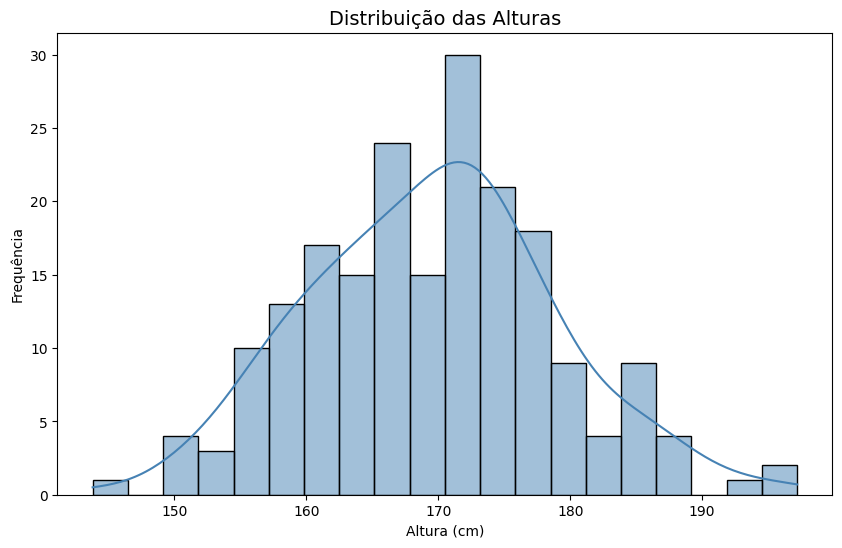

In [ ]:
# 1. Histograma
plt.figure(figsize=(10, 6))
sns.histplot(df['Altura'], bins=20, kde=True, color='steelblue')
plt.title('Distribuição das Alturas', fontsize=14)
plt.xlabel('Altura (cm)')
plt.ylabel('Frequência')
plt.show()

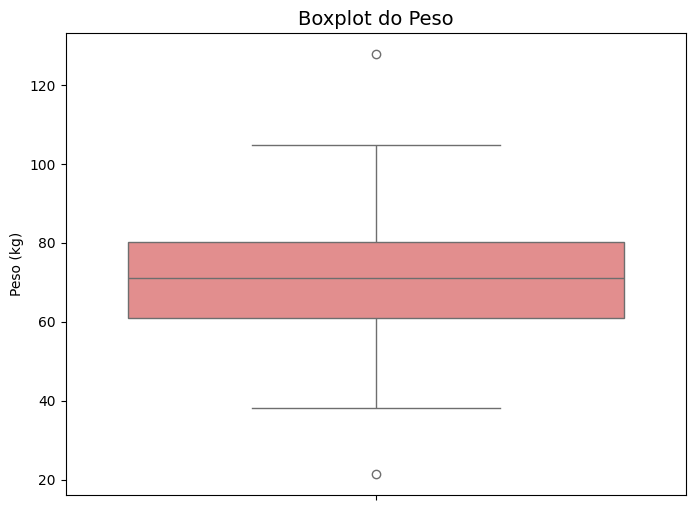

In [ ]:
# 2. Boxplot
plt.figure(figsize=(8, 6))
sns.boxplot(y=df['Peso'], color='lightcoral')
plt.title('Boxplot do Peso', fontsize=14)
plt.ylabel('Peso (kg)')
plt.show()

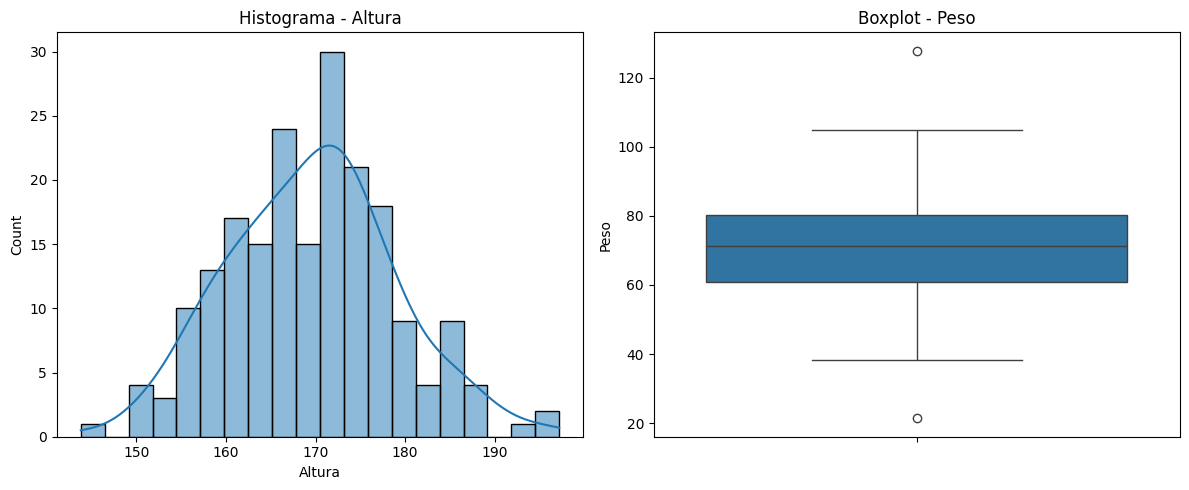

In [ ]:
# 3. Subplots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(df['Altura'], bins=20, kde=True, ax=axes[0])
axes[0].set_title('Histograma - Altura')
sns.boxplot(y=df['Peso'], ax=axes[1])
axes[1].set_title('Boxplot - Peso')
plt.tight_layout()
plt.show()

In [ ]:
# 4. Médias
print(f"Altura média: {df['Altura'].mean():.2f} cm")
print(f"Peso médio: {df['Peso'].mean():.2f} kg")

Altura média: 169.59 cm
Peso médio: 71.29 kg


In [ ]:
# 5. Describe
print(df.describe())

           Altura        Peso
count  200.000000  200.000000
mean   169.592290   71.288023
std      9.310039   14.805057
min    143.802549   21.380990
25%    162.948723   60.912437
50%    169.958081   71.182590
75%    175.008525   80.308467
max    197.201692  127.790972


## Questão 2:
Uma empresa quer visualizar as vendas de 5 produtos em duas regiões diferentes.

```
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Dados
dados = {
    'Produto': ['A', 'B', 'C', 'D', 'E'],
    'Norte': [120, 150, 90, 200, 170],
    'Sul': [100, 130, 110, 160, 140]
}
df = pd.DataFrame(dados)
```
Perguntas:

1. Crie um gráfico de barras com Matplotlib mostrando as vendas de cada produto na região Norte. Use cores personalizadas.

2. Crie um gráfico de barras horizontais para a região Sul.

3. Crie um gráfico de barras lado a lado (agrupado) comparando as vendas do Norte e Sul para cada produto. Use Seaborn com hue.

4. Crie um gráfico de barras empilhadas mostrando o total de vendas por produto (Norte + Sul).

5. Adicione os valores numéricos sobre cada barra no gráfico do item 3. (Use: `bar_label`)

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Dados
dados = {
    'Produto': ['A', 'B', 'C', 'D', 'E'],
    'Norte': [120, 150, 90, 200, 170],
    'Sul': [100, 130, 110, 160, 140]
}
df = pd.DataFrame(dados)

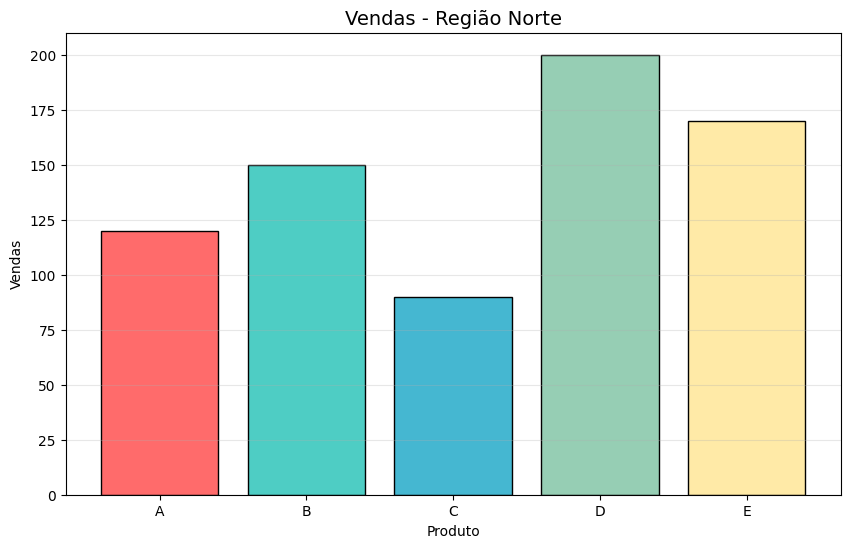

In [ ]:
# 1. Barras - Norte
plt.figure(figsize=(10, 6))
cores = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4', '#FFEAA7']
plt.bar(df['Produto'], df['Norte'], color=cores, edgecolor='black')
plt.title('Vendas - Região Norte', fontsize=14)
plt.xlabel('Produto')
plt.ylabel('Vendas')
plt.grid(True, alpha=0.3, axis='y')
plt.show()

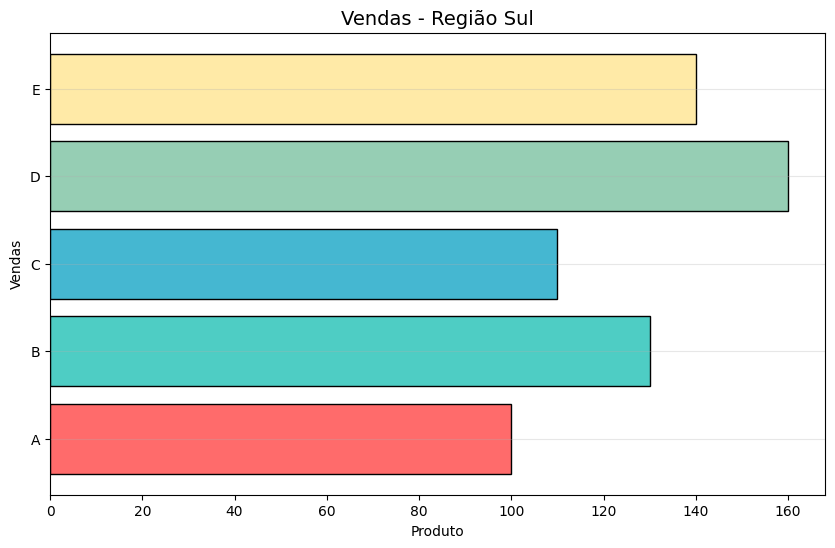

In [3]:
# 2. Barras - Sul
plt.figure(figsize=(10, 6))
cores = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4', '#FFEAA7']
plt.barh(df['Produto'], df['Sul'], color=cores, edgecolor='black')
plt.title('Vendas - Região Sul', fontsize=14)
plt.xlabel('Produto')
plt.ylabel('Vendas')
plt.grid(True, alpha=0.3, axis='y')
plt.show()

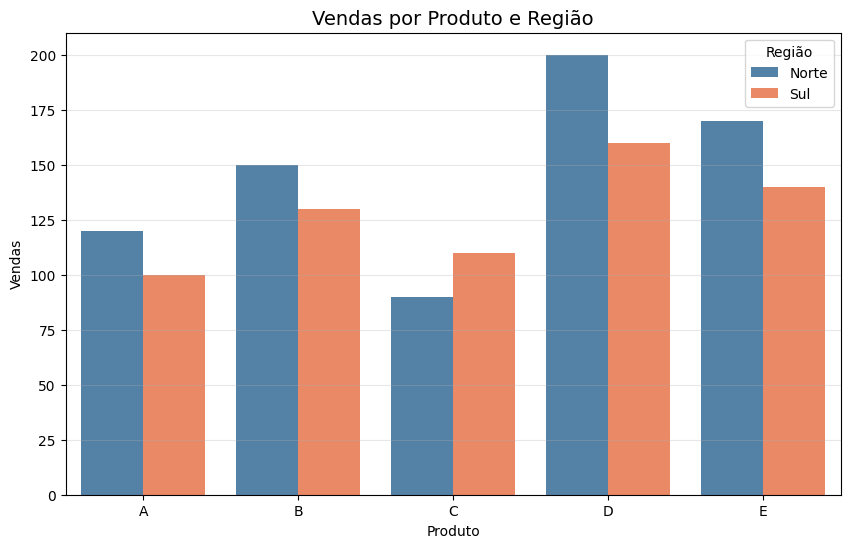

In [ ]:
# 3. Barras lado a lado (Seaborn)
df_long = df.melt(id_vars=['Produto'], var_name='Regiao', value_name='Vendas')
plt.figure(figsize=(10, 6))
sns.barplot(x='Produto', y='Vendas', hue='Regiao', data=df_long,
            palette=['steelblue', 'coral'])
plt.title('Vendas por Produto e Região', fontsize=14)
plt.legend(title='Região')
plt.grid(True, alpha=0.3, axis='y')
plt.show()

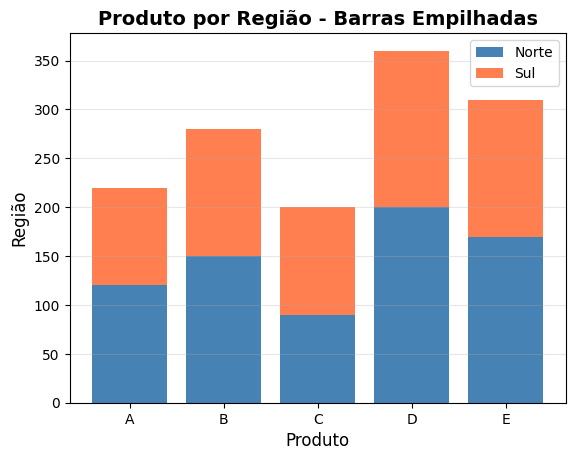

In [4]:
# 4. Barras empilhadas
plt.bar(df['Produto'], df['Norte'], label='Norte',
color='steelblue')
plt.bar(df['Produto'], df['Sul'],
bottom=df['Norte'], label='Sul', color='coral')
plt.title('Produto por Região - Barras Empilhadas', fontsize=14,
fontweight='bold')
plt.xlabel('Produto', fontsize=12)
plt.ylabel('Região', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3, axis='y')
plt.show()

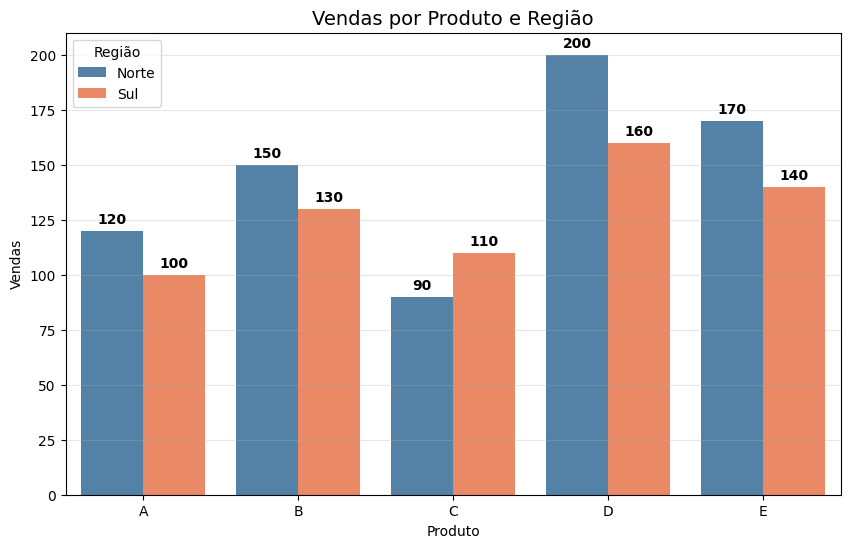

In [ ]:
from pandas.core.reshape import concat
# 5. Barras com valores
df_long = df.melt(id_vars=['Produto'], var_name='Regiao', value_name='Vendas')
plt.figure(figsize=(10, 6))
barras = sns.barplot(x='Produto', y='Vendas', hue='Regiao', data=df_long,
            palette=['steelblue', 'coral'])
plt.title('Vendas por Produto e Região', fontsize=14)
plt.legend(title='Região')
plt.grid(True, alpha=0.3, axis='y')
# Adicionando valores totais no topo das barras
for container in barras.containers:
    barras.bar_label(container, fmt='%.0f', fontsize=10, fontweight='bold', padding=3)
plt.show()

## Questão 3:
Você tem dados de horas de estudo e notas de 100 alunos. Explore a relação entre essas variáveis.

```
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Dados
np.random.seed(42)
dados = {
    'Horas_Estudo': np.random.uniform(1, 10, 100),
    'Nota': np.random.normal(5, 1.5, 100) + np.random.uniform(0, 0.5, 100) * 4
}
dados['Nota'] = dados['Nota'] + dados['Horas_Estudo'] * 0.4
df = pd.DataFrame(dados)
```
Perguntas:

1. Crie um scatter plot com Matplotlib mostrando a relação entre horas de estudo e nota.

2. Crie um scatter plot com Seaborn, adicionando uma linha de regressão com `regplot()`.

3. Calcule e exiba o coeficiente de correlação de Pearson entre as duas variáveis.

4. Crie um scatter plot onde os pontos são coloridos por uma terceira categoria: se o aluno estudou mais de 5 horas (crie essa coluna).

5. Adicione anotações no gráfico destacando o aluno com maior nota e o com menor nota.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Dados
np.random.seed(42)
dados = {
    'Horas_Estudo': np.random.uniform(1, 10, 100),
    'Nota': np.random.normal(5, 1.5, 100) + np.random.uniform(0, 0.5, 100) * 4
}
dados['Nota'] = dados['Nota'] + dados['Horas_Estudo'] * 0.4
df = pd.DataFrame(dados)

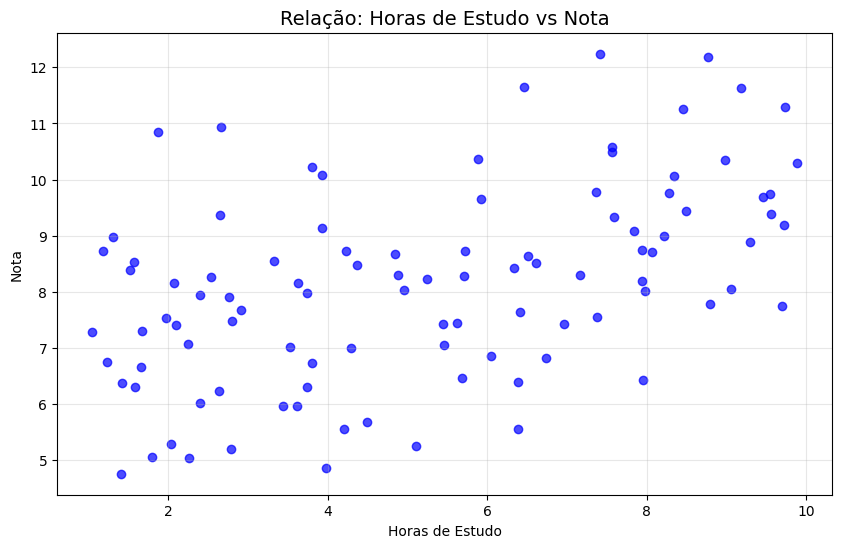

In [ ]:
# 1. Scatter plot
plt.figure(figsize=(10, 6))
plt.scatter(df['Horas_Estudo'], df['Nota'], color='blue', alpha=0.7)
plt.title('Relação: Horas de Estudo vs Nota', fontsize=14)
plt.xlabel('Horas de Estudo')
plt.ylabel('Nota')
plt.grid(True, alpha=0.3)
plt.show()

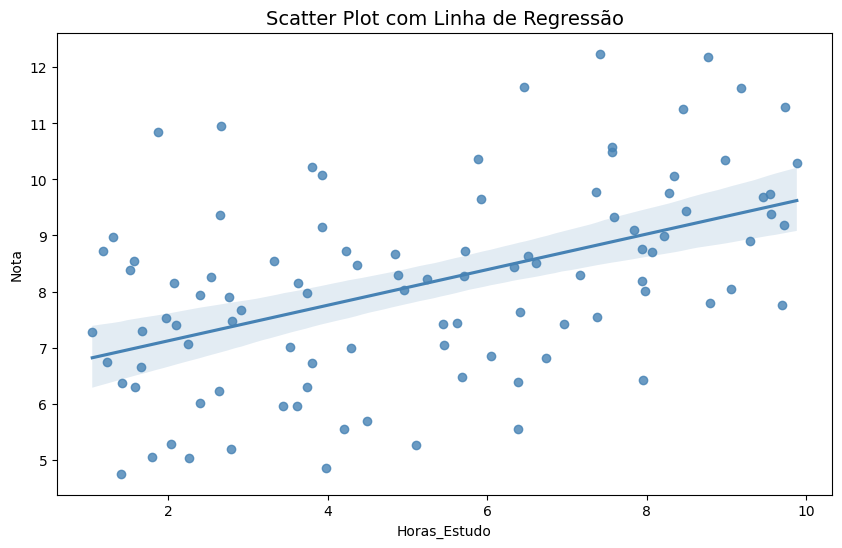

In [ ]:
# 2. Regressão
plt.figure(figsize=(10, 6))
sns.regplot(x='Horas_Estudo', y='Nota', data=df, color='steelblue')
plt.title('Scatter Plot com Linha de Regressão', fontsize=14)
plt.show()

In [ ]:
# 3. Correlação
corr = df['Horas_Estudo'].corr(df['Nota'])
print(f"Coeficiente de Correlação: {corr:.3f}")

Coeficiente de Correlação: 0.489


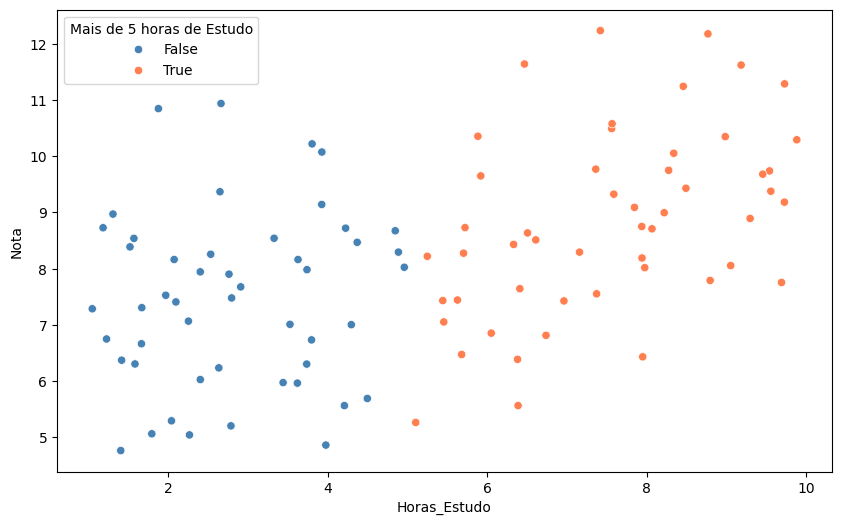

In [ ]:
# 4. scatter plot onde os pontos são coloridos por estudo > 5h
df['Estudo5h'] = df['Horas_Estudo'] > 5
plt.figure(figsize=(10, 6))
sns.scatterplot(x='Horas_Estudo', y='Nota', hue='Estudo5h', data=df, palette=['steelblue', 'coral'])
plt.legend(title='Mais de 5 horas de Estudo')

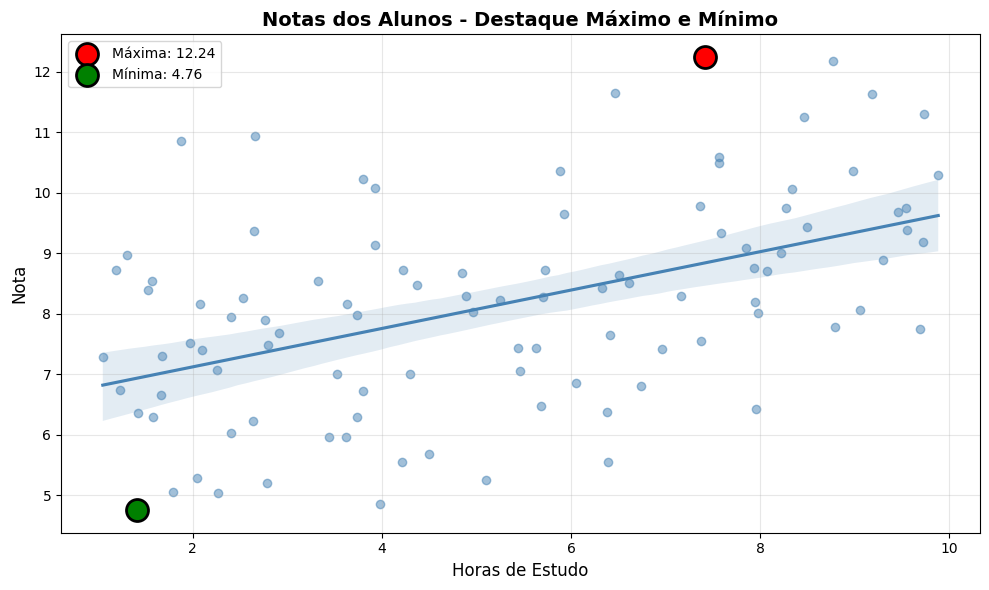

In [ ]:
# 5. anotações no gráfico destacando o aluno com maior nota e o com menor nota
# Encontrando máximo e mínimo
max_nota = df.loc[df['Nota'].idxmax()]  # Aluno com maior nota
min_nota = df.loc[df['Nota'].idxmin()]  # Aluno com menor nota

# Criando o gráfico
plt.figure(figsize=(10, 6))

# Gráfico base com regressão
sns.regplot(x='Horas_Estudo', y='Nota', data=df,
            color='steelblue', scatter_kws={'alpha': 0.5})

# Destacando o MÁXIMO (VERMELHO)
plt.scatter(max_nota['Horas_Estudo'], max_nota['Nota'],
            color='red', s=250,
            edgecolors='black', linewidth=2,
            label=f'Máxima: {max_nota["Nota"]:.2f}')

# Destacando o MÍNIMO (VERDE)
plt.scatter(min_nota['Horas_Estudo'], min_nota['Nota'],
            color='green', s=250,
            edgecolors='black', linewidth=2,
            label=f'Mínima: {min_nota["Nota"]:.2f}')

plt.title('Notas dos Alunos - Destaque Máximo e Mínimo', fontsize=14, fontweight='bold')
plt.xlabel('Horas de Estudo', fontsize=12)
plt.ylabel('Nota', fontsize=12)
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Questão 4:
Use o dataset Iris (já disponível no Seaborn) para explorar as relações entre as variáveis.

```
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Carregando o dataset Iris
iris = sns.load_dataset('iris')
print(iris.head())
```
Perguntas:

1. Crie um pairplot do dataset Iris, colorindo os pontos por espécie (species).

2. Calcule a matriz de correlação das variáveis numéricas.

3. Crie um heatmap da matriz de correlação, com anotações (annot=True).

4. Qual variável tem maior correlação com `petal_length`?

5. Crie um pairplot apenas com as variáveis `sepal_length`, `sepal_width` e `petal_length`.

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Carregando o dataset Iris
iris = sns.load_dataset('iris')
print(iris.head())

   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa


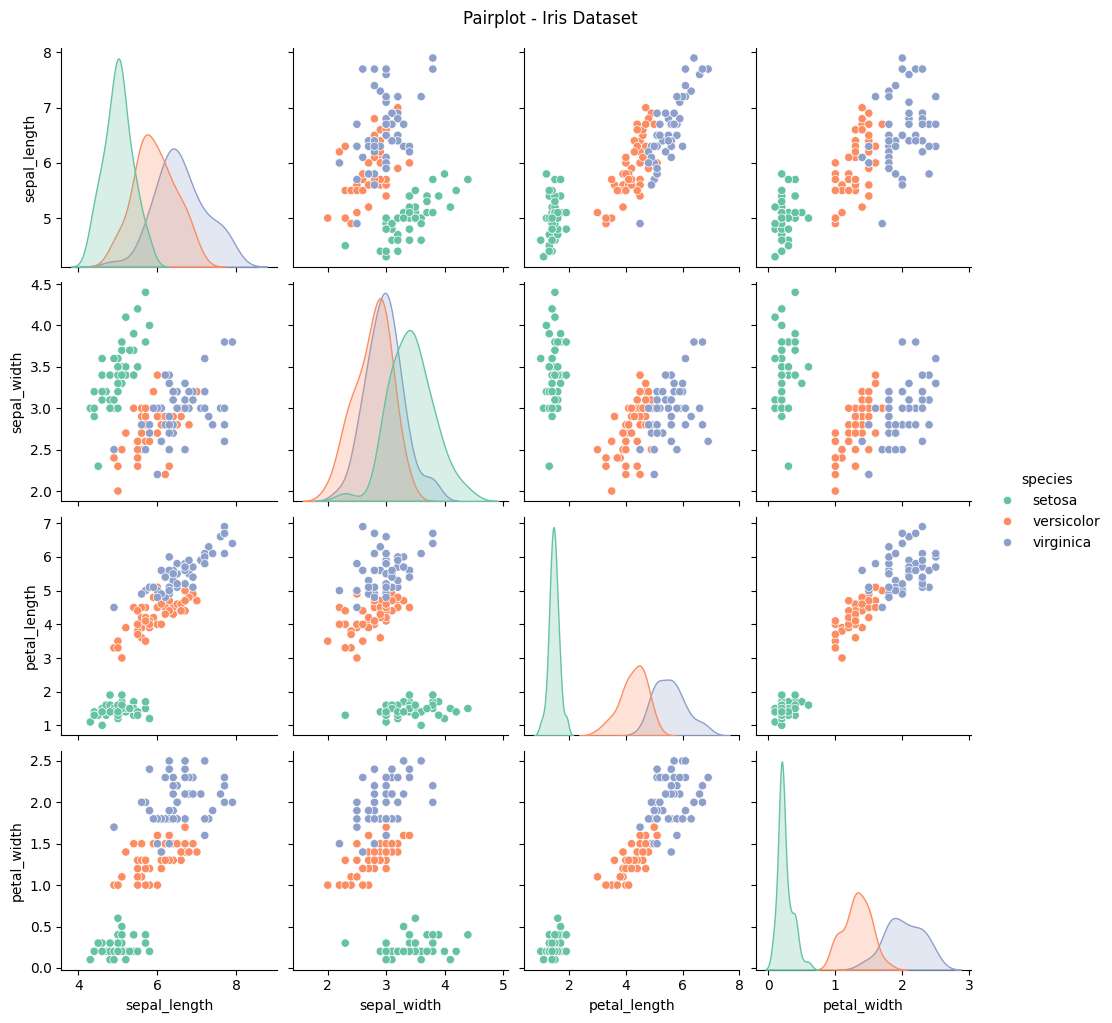

In [ ]:
# 1. Pairplot
sns.pairplot(iris, hue='species', palette='Set2')
plt.suptitle('Pairplot - Iris Dataset', y=1.02)
plt.show()

In [ ]:
# 2. Matriz de correlação
corr = iris.select_dtypes(include=[float]).corr()
print(corr)

              sepal_length  sepal_width  petal_length  petal_width
sepal_length      1.000000    -0.117570      0.871754     0.817941
sepal_width      -0.117570     1.000000     -0.428440    -0.366126
petal_length      0.871754    -0.428440      1.000000     0.962865
petal_width       0.817941    -0.366126      0.962865     1.000000


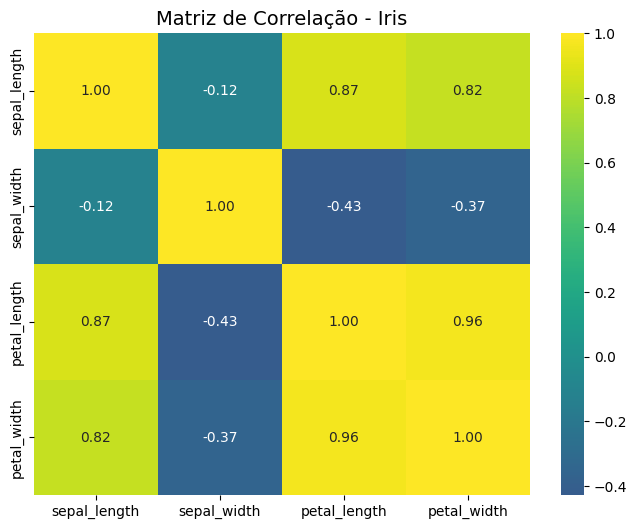

In [ ]:
# 3. Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='viridis', center=0, fmt='.2f')
plt.title('Matriz de Correlação - Iris', fontsize=14)
plt.show()

In [ ]:
# 4. Maior correlação com petal_length
print(corr['petal_length'].sort_values(ascending=False))

petal_length    1.000000
petal_width     0.962865
sepal_length    0.871754
sepal_width    -0.428440
Name: petal_length, dtype: float64


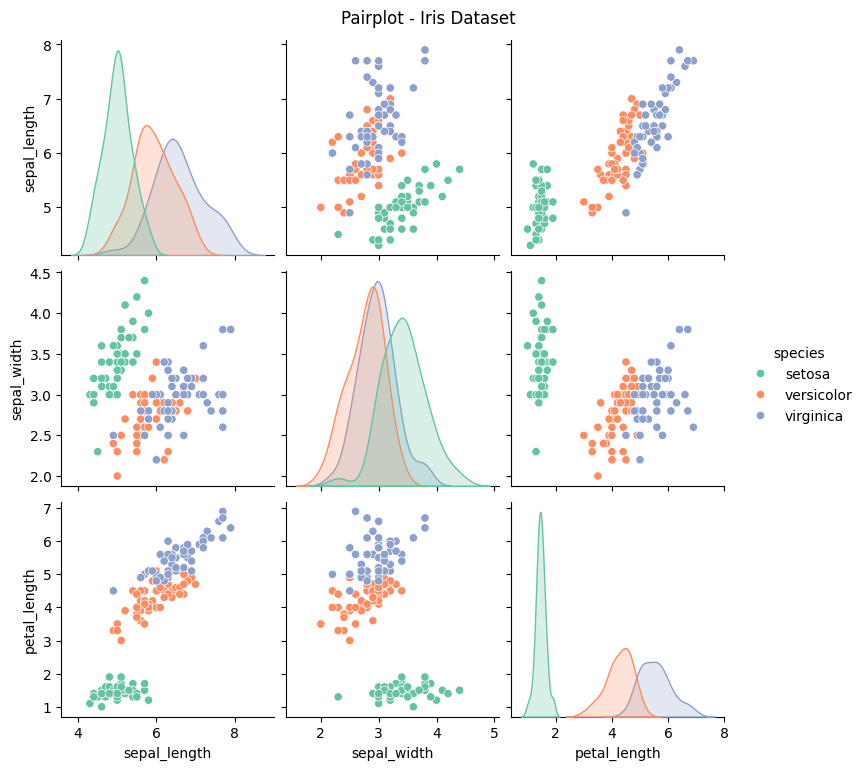

In [ ]:
# 5. pairplot apenas com as variáveis sepal_length, sepal_width e petal_length
sns.pairplot(iris, vars=['sepal_length', 'sepal_width', 'petal_length'],
             hue='species', palette='Set2')
plt.suptitle('Pairplot - Iris Dataset', y=1.02)
plt.show()

## Questão 5:
Uma loja registrou suas vendas diárias durante 3 meses. Visualize a tendência e padrões.

```
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Dados
np.random.seed(42)
datas = pd.date_range('2024-01-01', periods=90, freq='D')
vendas = 1000 + np.cumsum(np.random.normal(0, 10, 90))  # Tendência com ruído
vendas = vendas + 50 * np.sin(np.arange(90) * 2 * np.pi / 7)  # Padrão semanal

df = pd.DataFrame({
    'Data': datas,
    'Vendas': vendas
})
```
Perguntas:

1. Crie um line plot com Seaborn mostrando a evolução diária das vendas.

2. Crie um line plot com Matplotlib, adicionando marcadores (`marker='o'`) e alterando a cor para verde.

3. Adicione uma linha horizontal representando a média das vendas (`plt.axhline()`).

4. Calcule a média de vendas por dia da semana (Segunda, Terça, etc.) usando `df['Data'].dt.dayofweek`.

5. Crie um gráfico de linha com área preenchida (`plt.fill_between()`) mostrando as vendas e a média.



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Dados
np.random.seed(42)
datas = pd.date_range('2024-01-01', periods=90, freq='D')
vendas = 1000 + np.cumsum(np.random.normal(0, 10, 90))  # Tendência com ruído
vendas = vendas + 50 * np.sin(np.arange(90) * 2 * np.pi / 7)  # Padrão semanal

df = pd.DataFrame({
    'Data': datas,
    'Vendas': vendas
})

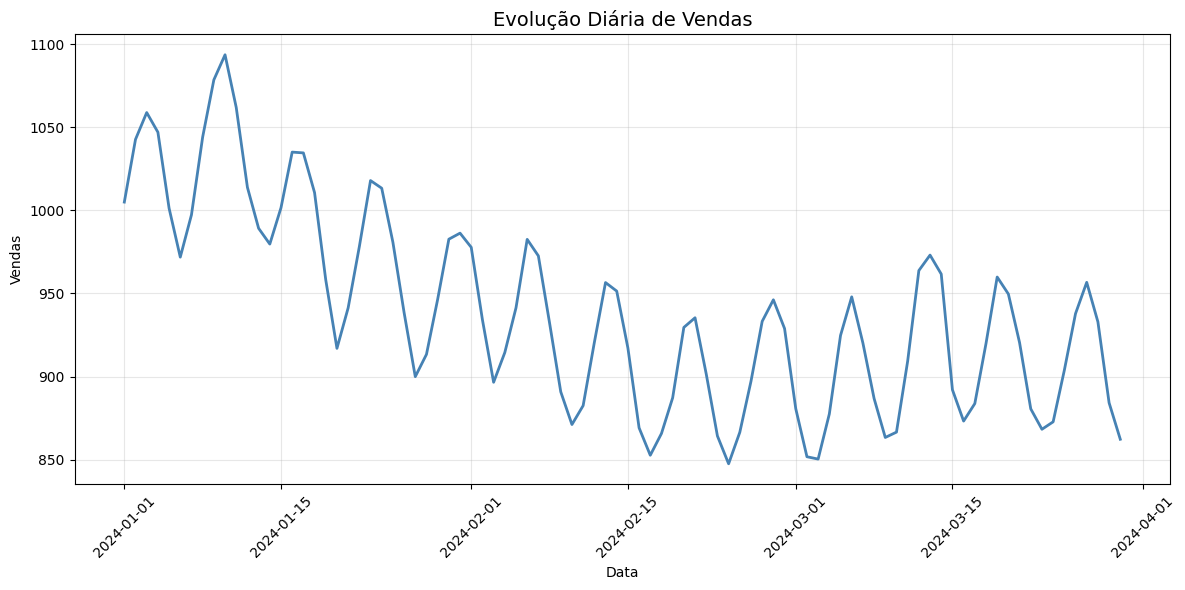

In [ ]:
# 1. Line plot
plt.figure(figsize=(12, 6))
sns.lineplot(x='Data', y='Vendas', data=df, color='steelblue', linewidth=2)
plt.title('Evolução Diária de Vendas', fontsize=14)
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

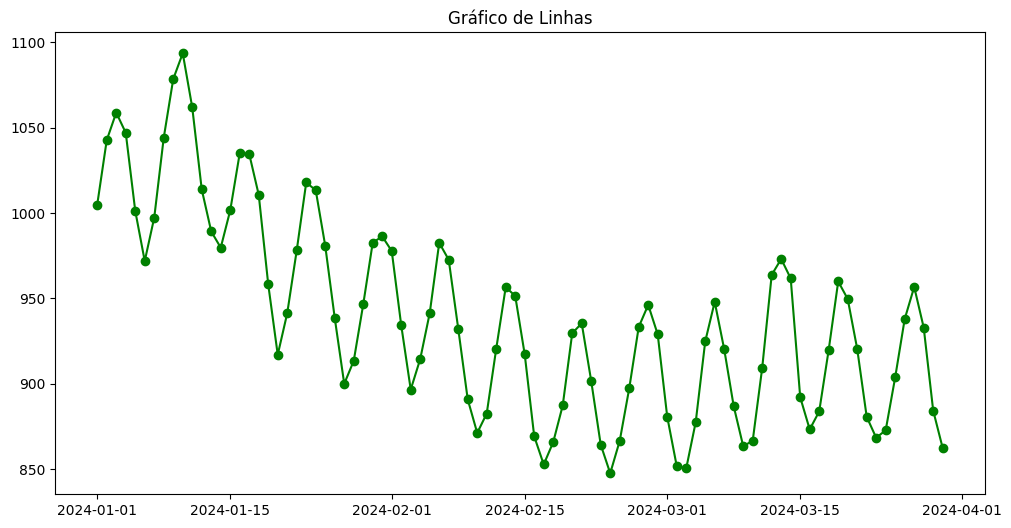

In [ ]:
# 2. line plot com matplot
x = df['Data']
y = df['Vendas']
plt.figure(figsize=(12, 6))
plt.plot(x, y, color='green', marker ='o')
plt.title ('Gráfico de Linhas')
plt.show()

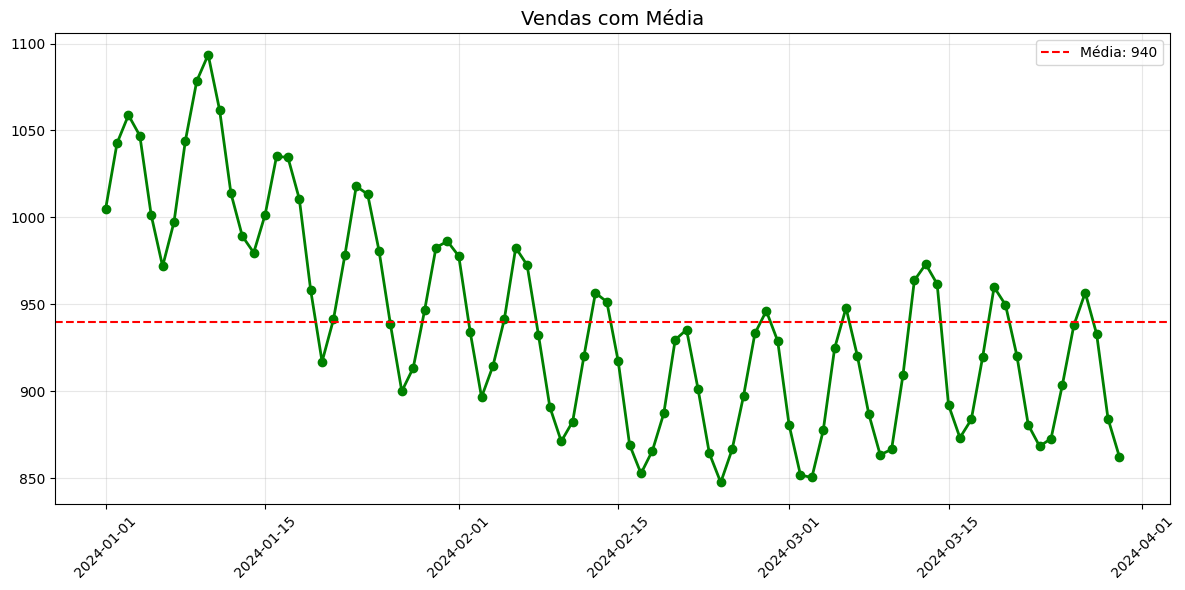

In [ ]:
# 3. Com linha da média
media = df['Vendas'].mean()
plt.figure(figsize=(12, 6))
plt.plot(df['Data'], df['Vendas'], color='green', marker ='o', linewidth=2)
plt.axhline(y=media, color='red', linestyle='--', label=f'Média: {media:.0f}')
plt.legend()
plt.title('Vendas com Média', fontsize=14)
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# 4. Média por dia da semana
df['Dia_Semana'] = df['Data'].dt.day_name()
media_semana = df.groupby('Dia_Semana')['Vendas'].mean()
print(media_semana)

Dia_Semana
Friday       914.990387
Monday       940.930998
Saturday     889.632368
Sunday       902.890545
Thursday     961.017697
Tuesday      980.383346
Wednesday    986.120628
Name: Vendas, dtype: float64


Text(0.5, 1.0, 'Vendas com Média')

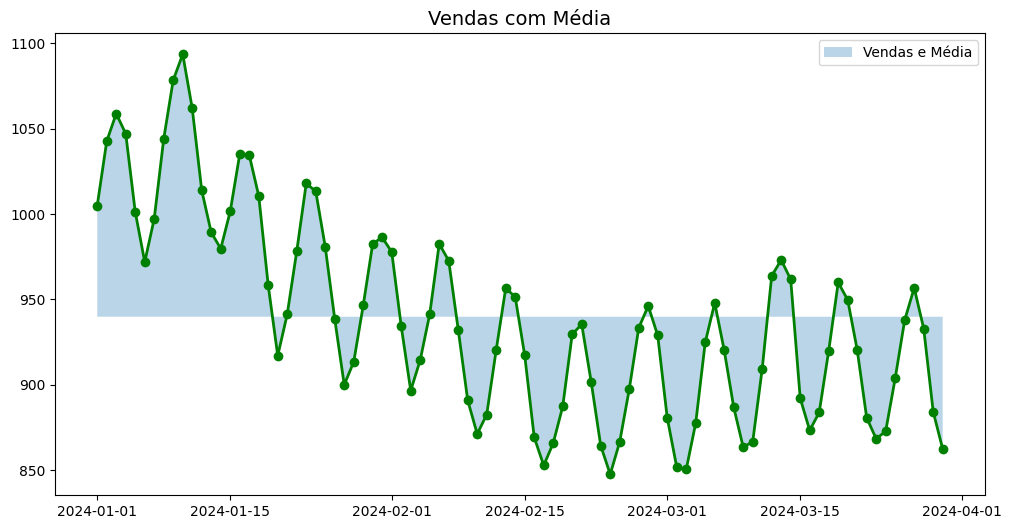

In [ ]:
# linha com área preenchida (plt.fill_between()) mostrando as vendas e a média
plt.figure(figsize=(12, 6))
plt.plot(df['Data'], df['Vendas'], color='green', marker ='o', linewidth=2)
plt.fill_between(df['Data'], df['Vendas'], media, alpha=0.3, label='Vendas e Média')
plt.legend()
plt.title('Vendas com Média', fontsize=14)